# Le rail suit-il la France qui grandit ?

Projet de Python pour la data science (ENSAE, 2e année) : Éléonore SAMSON, Mathilde DECOUCHON et Tamsir NDONG.

Entre 2017 et 2023, certaines communes gagnent des habitants, pendant que d'autres en perde. Le réseau ferroviaire devient de plus en plus un enjeu de souveraineté écologique et économique. Ainsi, on se demande si la fréquentation des gares suit ces évolutions, et quels liens avec la voiture. 

Nos Questionnements: 
1. Où va la population ?
2. Comment évolue la fréquentation des gares ?
3. Le rail suit-il la population ?
4. Qui dépend de la voiture, et qui vit loin d'une gare ?
5. Bonus: le train face à l'avion sur les liaisons intérieures. 

Ce notebook a vocation à résumer notre étude. 

In [1]:
import os
import sys

import geopandas as gpd
import numpy as np
import pandas as pd
import yaml

# on se place à la racine du projet
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

with open("config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

from src.variables import build_parts_croissance
import src.visualisation as vis

# la base finale : une ligne par commune, une ligne par gare et par année, une ligne par liaison aérienne
communes = gpd.read_parquet("data/clean/base_finale/base_finale_communes_variables.parquet")
gares_annees = pd.read_parquet("data/clean/base_finale/base_finale_gares_annees.parquet")
liaisons = pd.read_parquet("data/clean/base_finale/base_finale_liaisons_co2.parquet")
debut, fin = config["annee_debut"], config["annee_fin"]

## 1. Les données

| Source | Ce qu'on en tire | Notebook |
|---|---|---|
| cartiflette (IGN, INSEE) | contours des communes au 1er janvier 2026 | `01_donnees`, 1.1 |
| INSEE, recensement 2023 | population, naissances, décès ; modes de déplacement domicile-travail | 1.2 et 1.3 |
| SNCF Open Data | position des gares et voyageurs par gare et par année | 1.4 |
| SDES | voitures des particuliers par commune | 1.5 |
| DGAC (bonus) | passagers par liaison aérienne intérieure | 1.6 |
| ADEME, Base Carbone (bonus) | CO2 par passager et par kilomètre, selon le mode | 1.7 |

Voici les choix qui structurent notre étude: 
- la période 2017-2023, qui suit celle du recensement 2023 ;
- les communes au 1er janvier 2026, en France métropolitaine ;
- la part de la voiture n'est calculée que pour les communes d'au moins 1 000 actifs.

In [2]:
print(f"{len(communes):,} communes".replace(",", " "))
nb_gares = f"{gares_annees['code_uic'].nunique():,}".replace(",", " ")
print(f"{nb_gares} gares, suivies de {gares_annees['annee'].min()} à {gares_annees['annee'].max()}")
print(f"{len(liaisons)} liaisons aériennes intérieures")

34 746 communes
2 779 gares, suivies de 2017 à 2023
52 liaisons aériennes intérieures


## 2. Où va la population ?

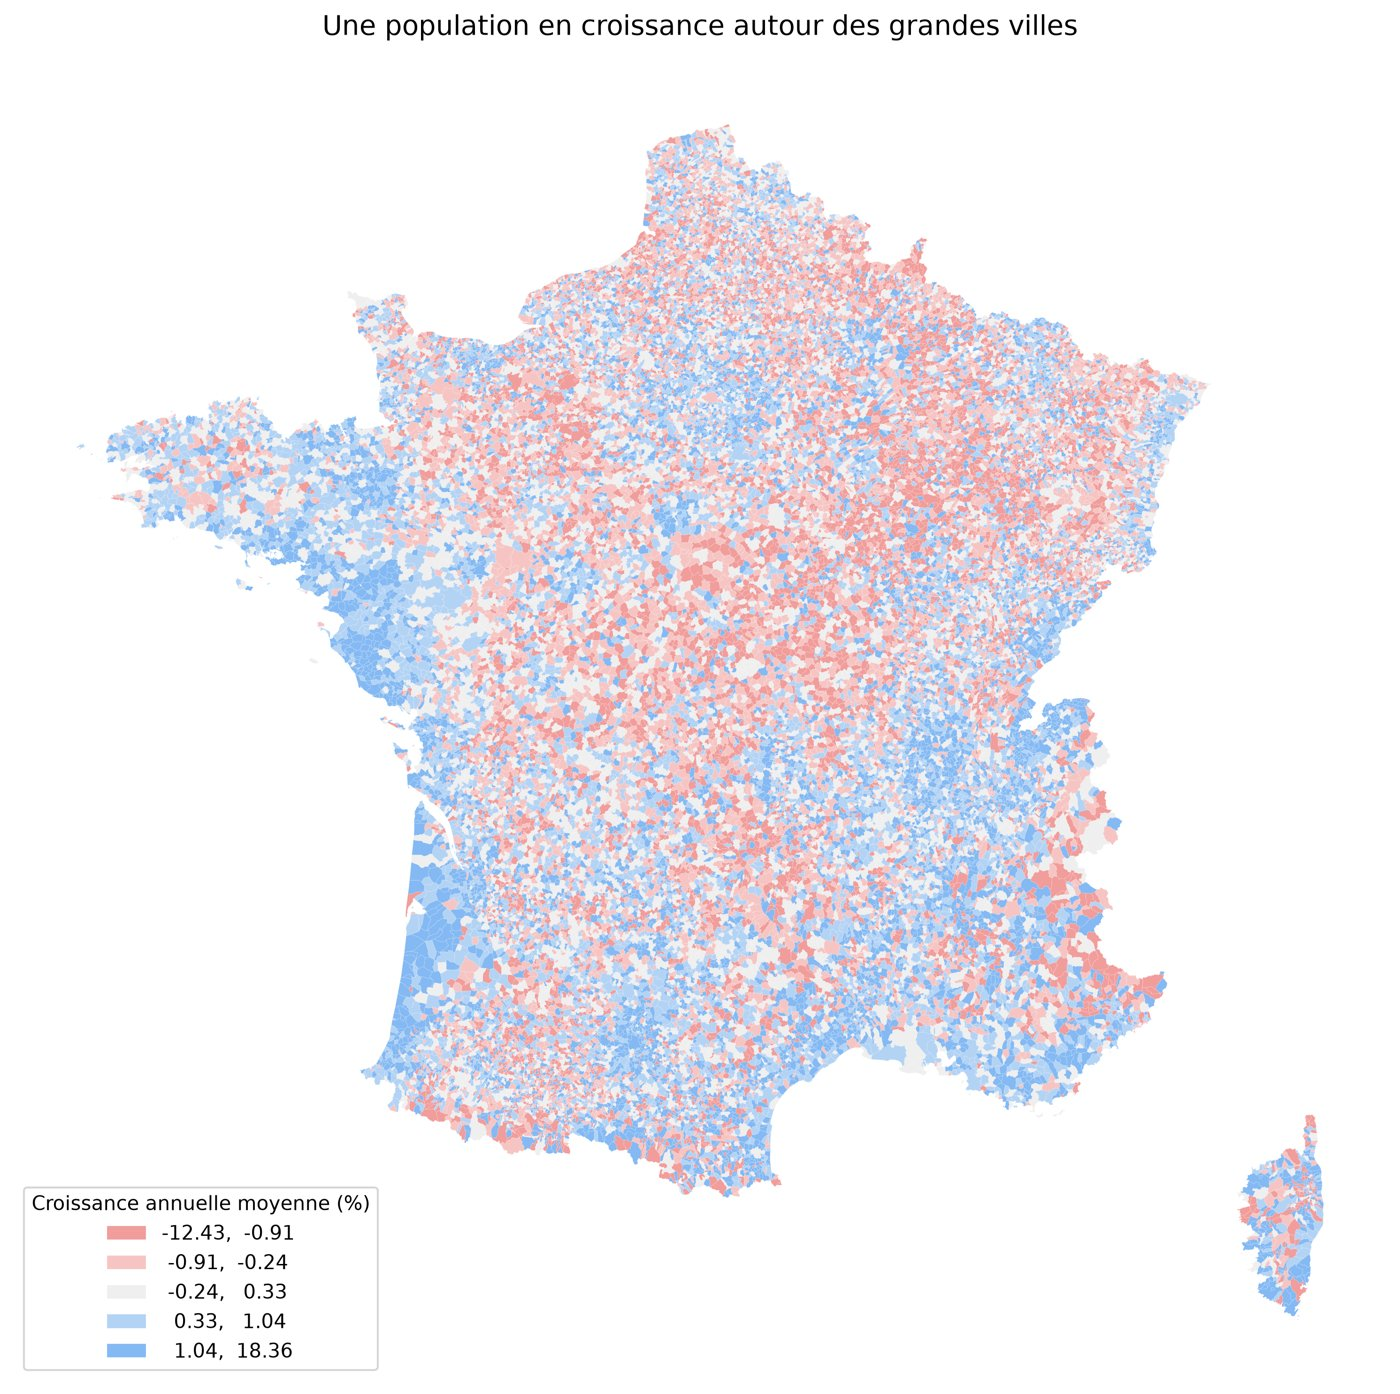

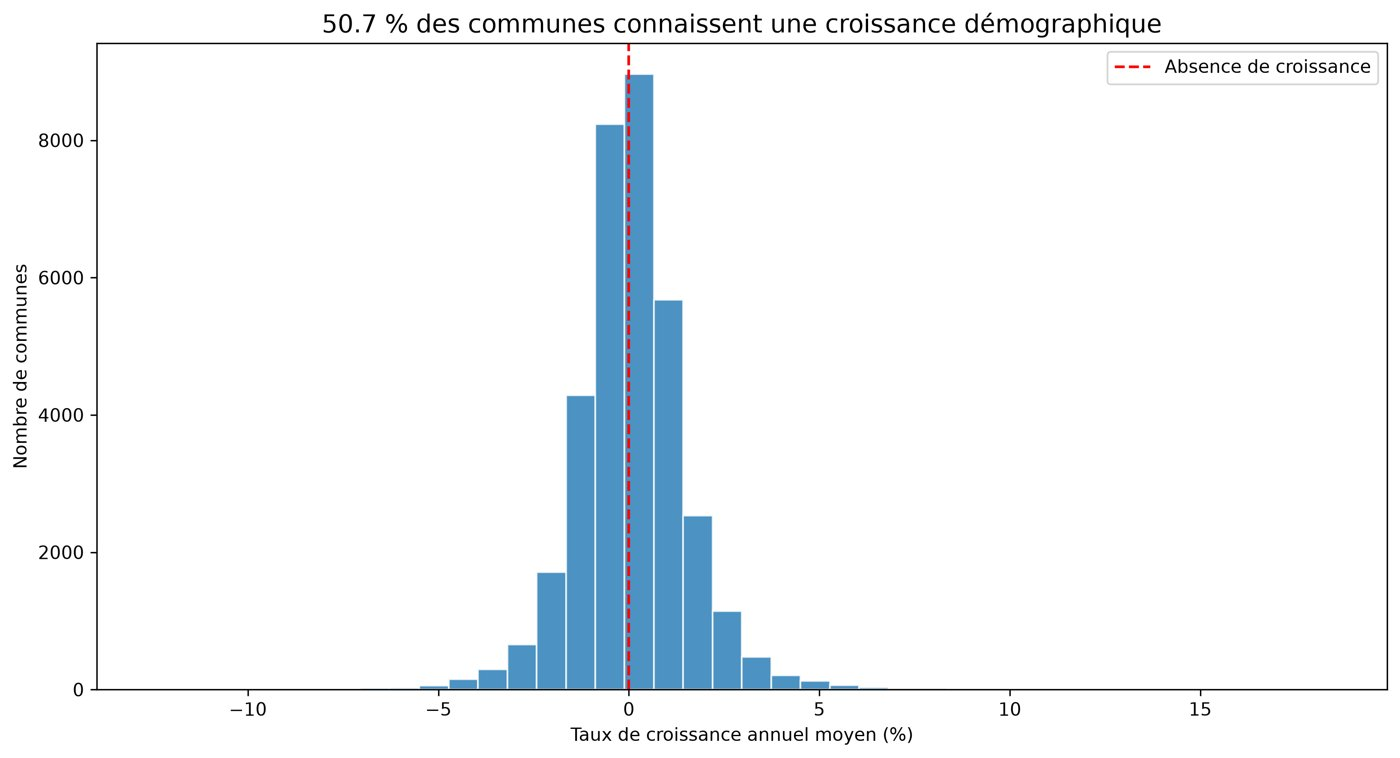

In [3]:
vis.plot_figure("01_croissance_demographique.png")
vis.plot_figure("03_histogramme_croissance.png")

In [4]:
evolution = communes["pop_2023"].sum() / communes["pop_2017"].sum() * 100 - 100
declin = (communes["tcam_pop_2017_2023"].dropna() < 0).mean() * 100
print(f"Population : {evolution:+.1f} % entre {debut} et {fin}")
print(f"Communes qui perdent des habitants : {declin:.0f} %")
print(f"Taux de croissance médian : {communes['tcam_pop_2017_2023'].median():+.2f} % par an")

Population : +2.4 % entre 2017 et 2023
Communes qui perdent des habitants : 48 %
Taux de croissance médian : +0.04 % par an


La population augmente légèrement, mais cette hausse cache des trajectoires opposées : près d'une commune
sur deux perd des habitants. La croissance se concentre autour des grandes villes, sur la façade atlantique
et dans le Sud.

## 3. Comment évolue la fréquentation des gares ?

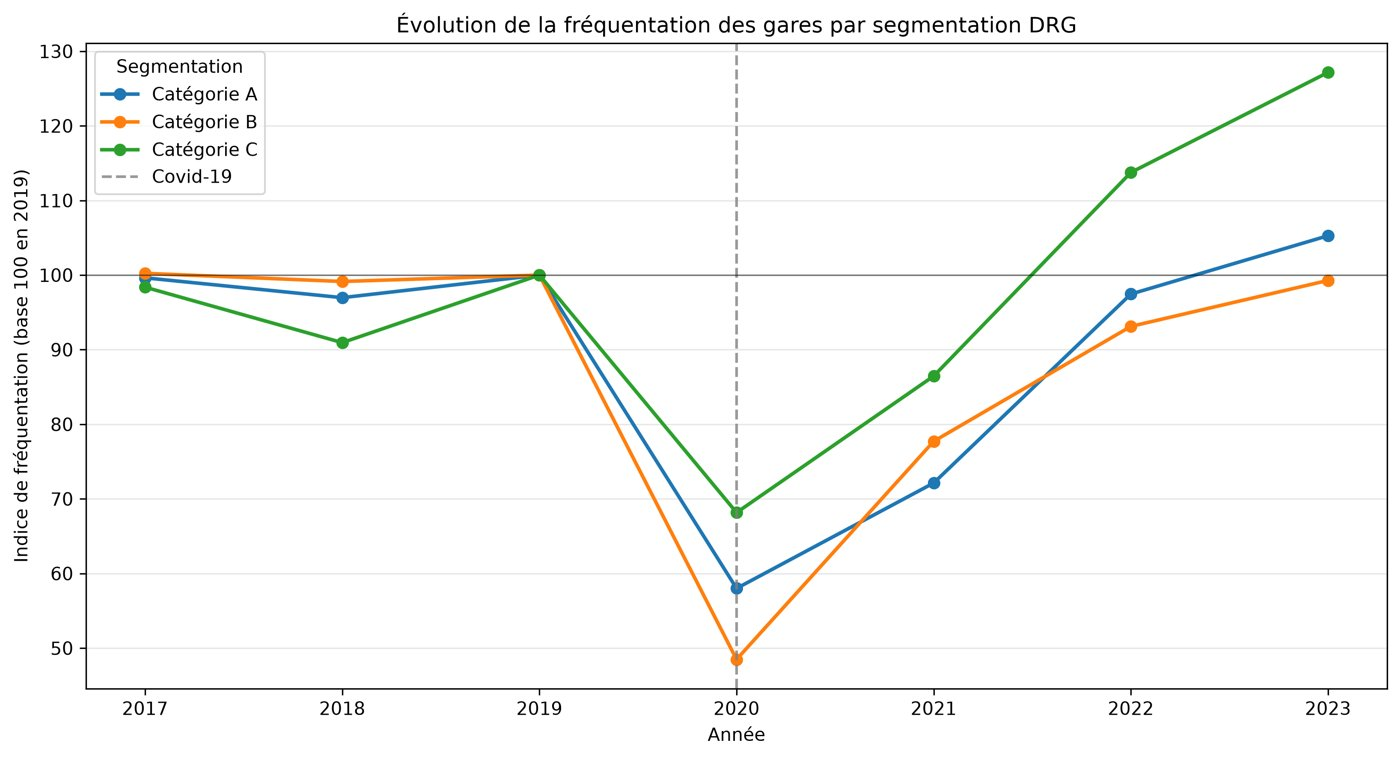

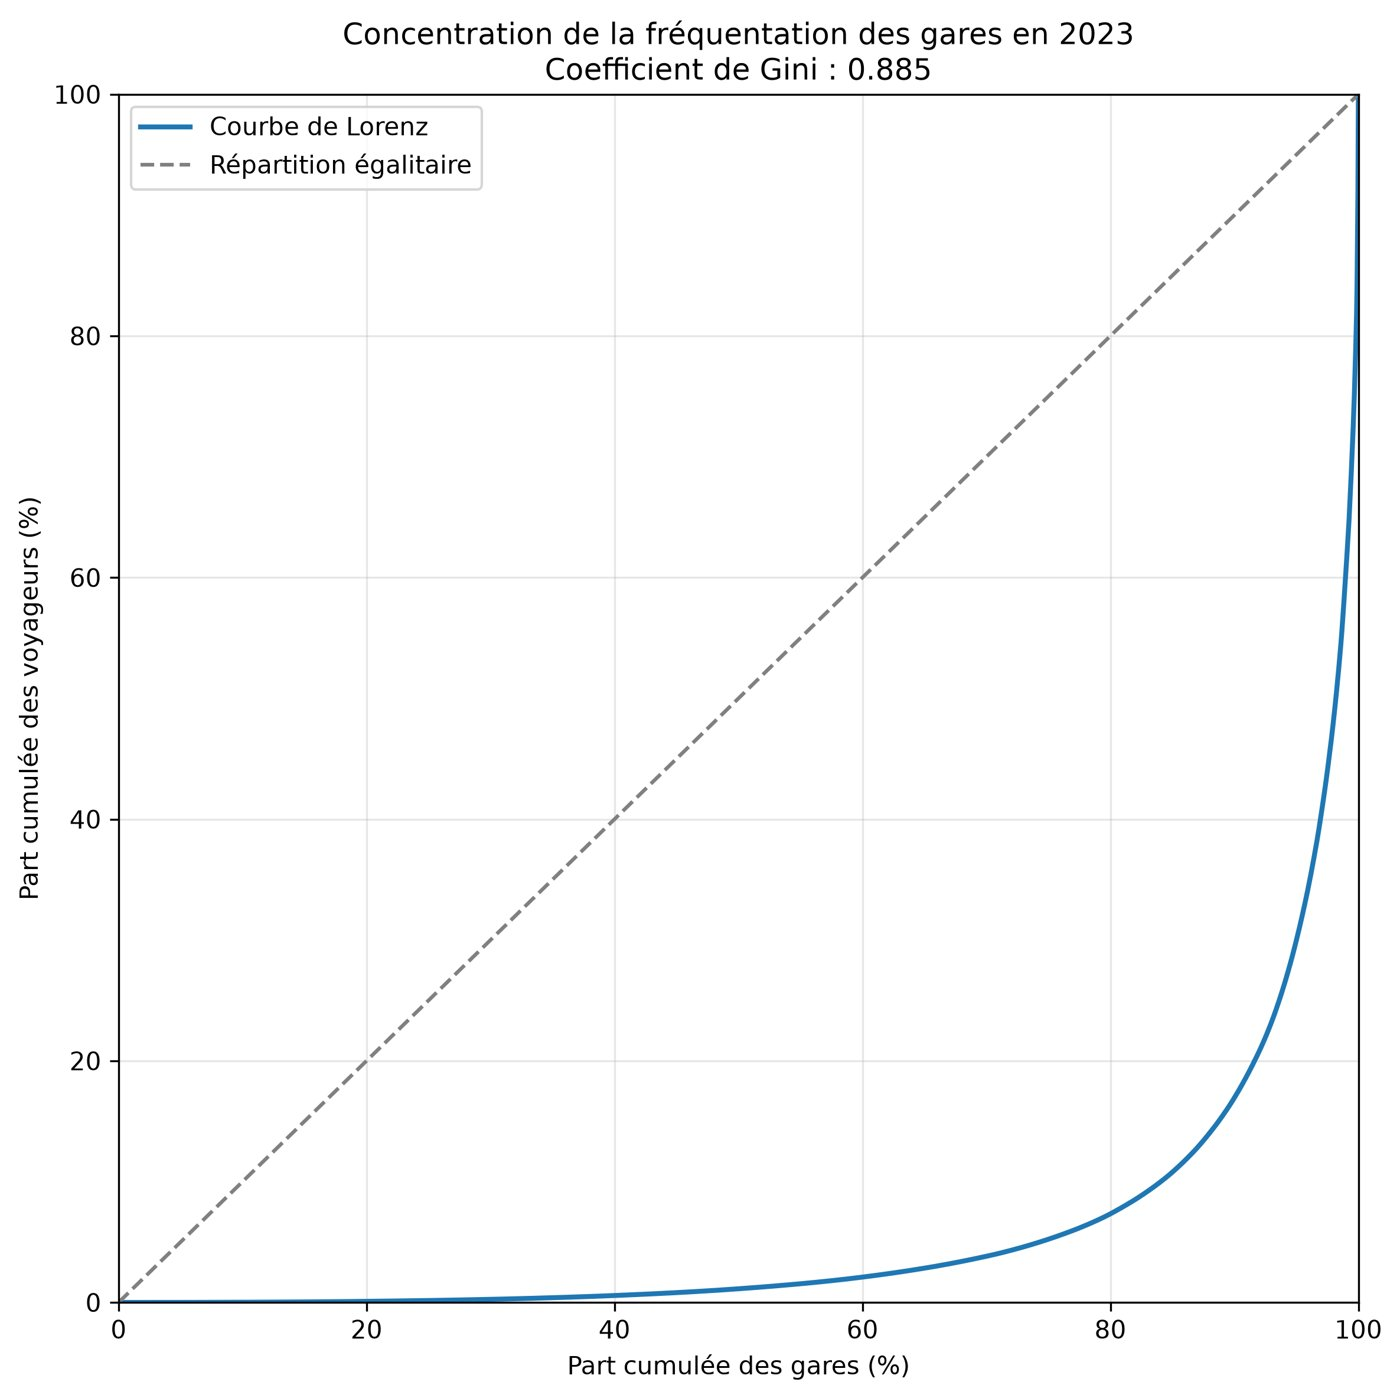

In [5]:
vis.plot_figure("04_voyageurs_base_100.png")
vis.plot_figure("05_courbe_Lorenz_voyageurs.png")

In [6]:
par_annee = gares_annees.groupby("annee")["voyageurs"].sum()
print(f"Voyageurs : {par_annee[fin] / par_annee[debut] * 100 - 100:+.1f} % entre {debut} et {fin}")
print(f"Covid : {par_annee[2020] / par_annee[2019] * 100 - 100:+.0f} % entre 2019 et 2020")

# coefficient de Gini des voyageurs par gare (0 : tous égaux, 1 : une seule gare)
voyageurs = np.sort(gares_annees.loc[gares_annees["annee"] == fin, "voyageurs"].to_numpy())
cumul = np.insert(np.cumsum(voyageurs) / voyageurs.sum(), 0, 0)
gini = 1 - 2 * np.trapezoid(cumul, np.linspace(0, 1, len(cumul)))
print(f"Gini des voyageurs par gare en {fin} : {gini:.2f}")

Voyageurs : +2.0 % entre 2017 et 2023
Covid : -48 % entre 2019 et 2020
Gini des voyageurs par gare en 2023 : 0.88


La fréquentation des gares a chuté avec le Covid, puis s'est redressée. Elle est très concentrée. En effet, une petite
partie des gares accueille l'essentiel des voyageurs.

## 4. Le rail suit-il la population ?

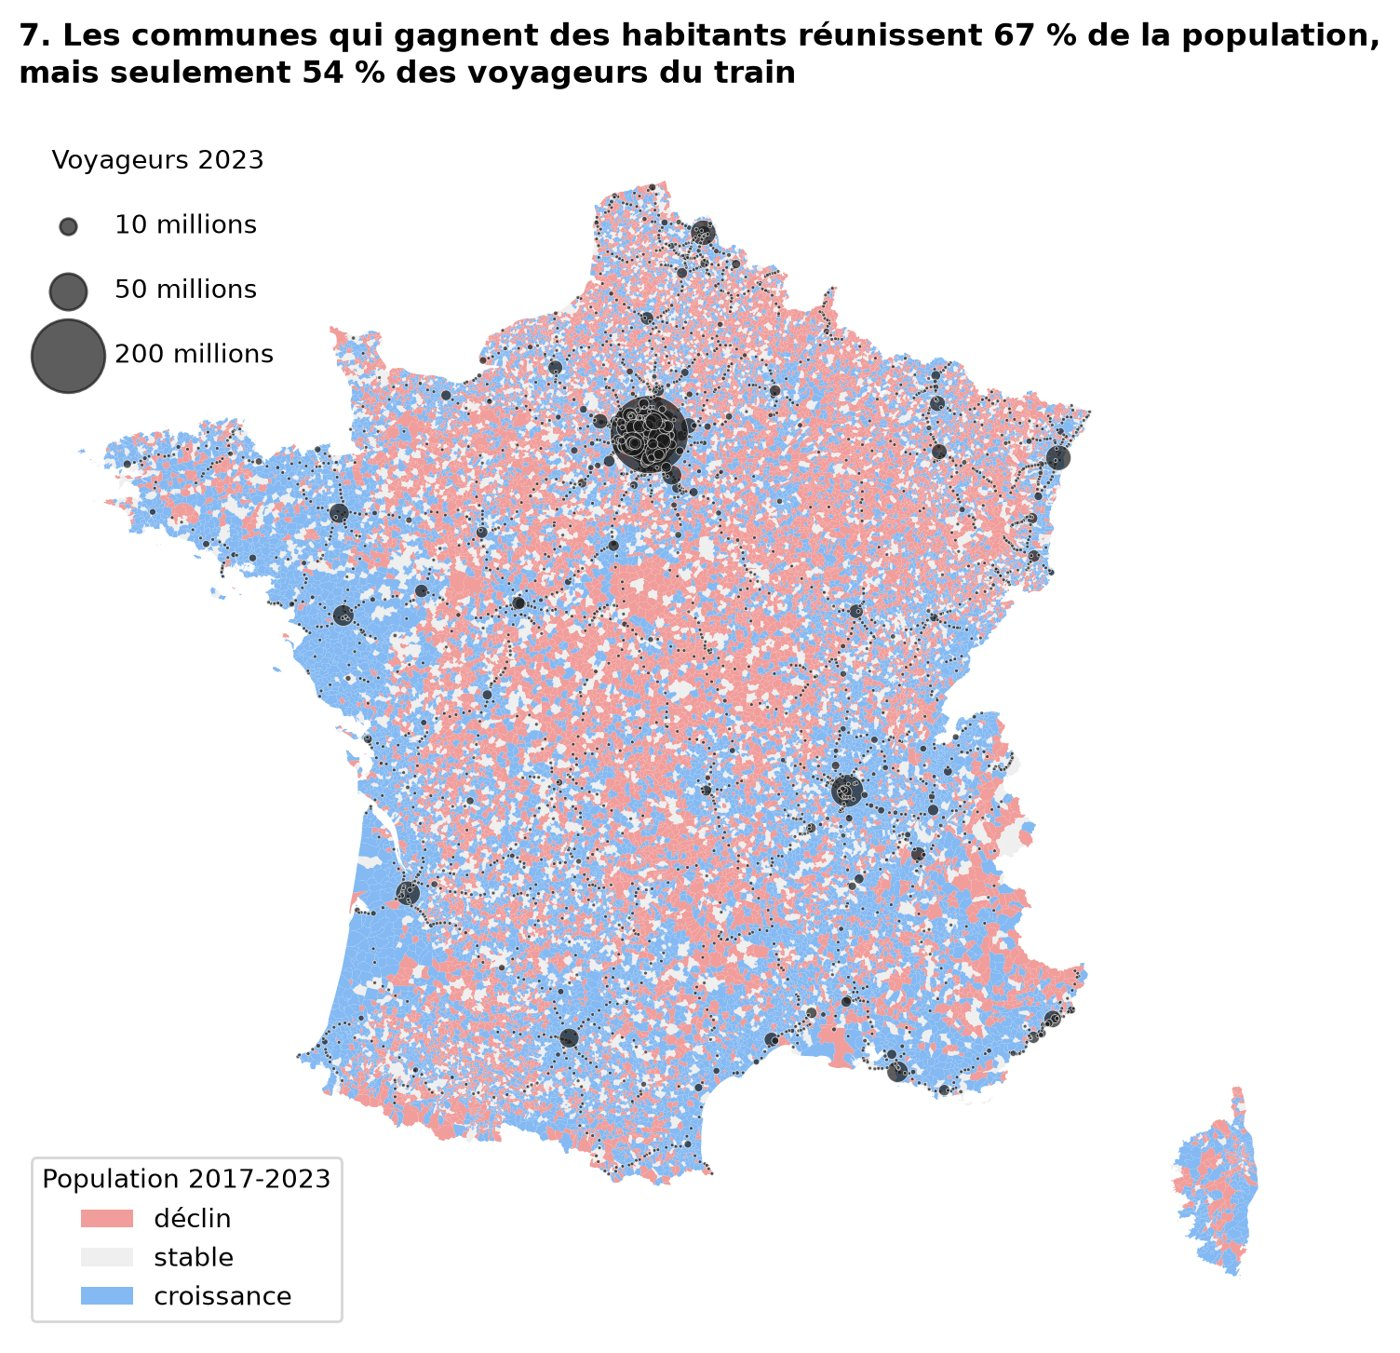

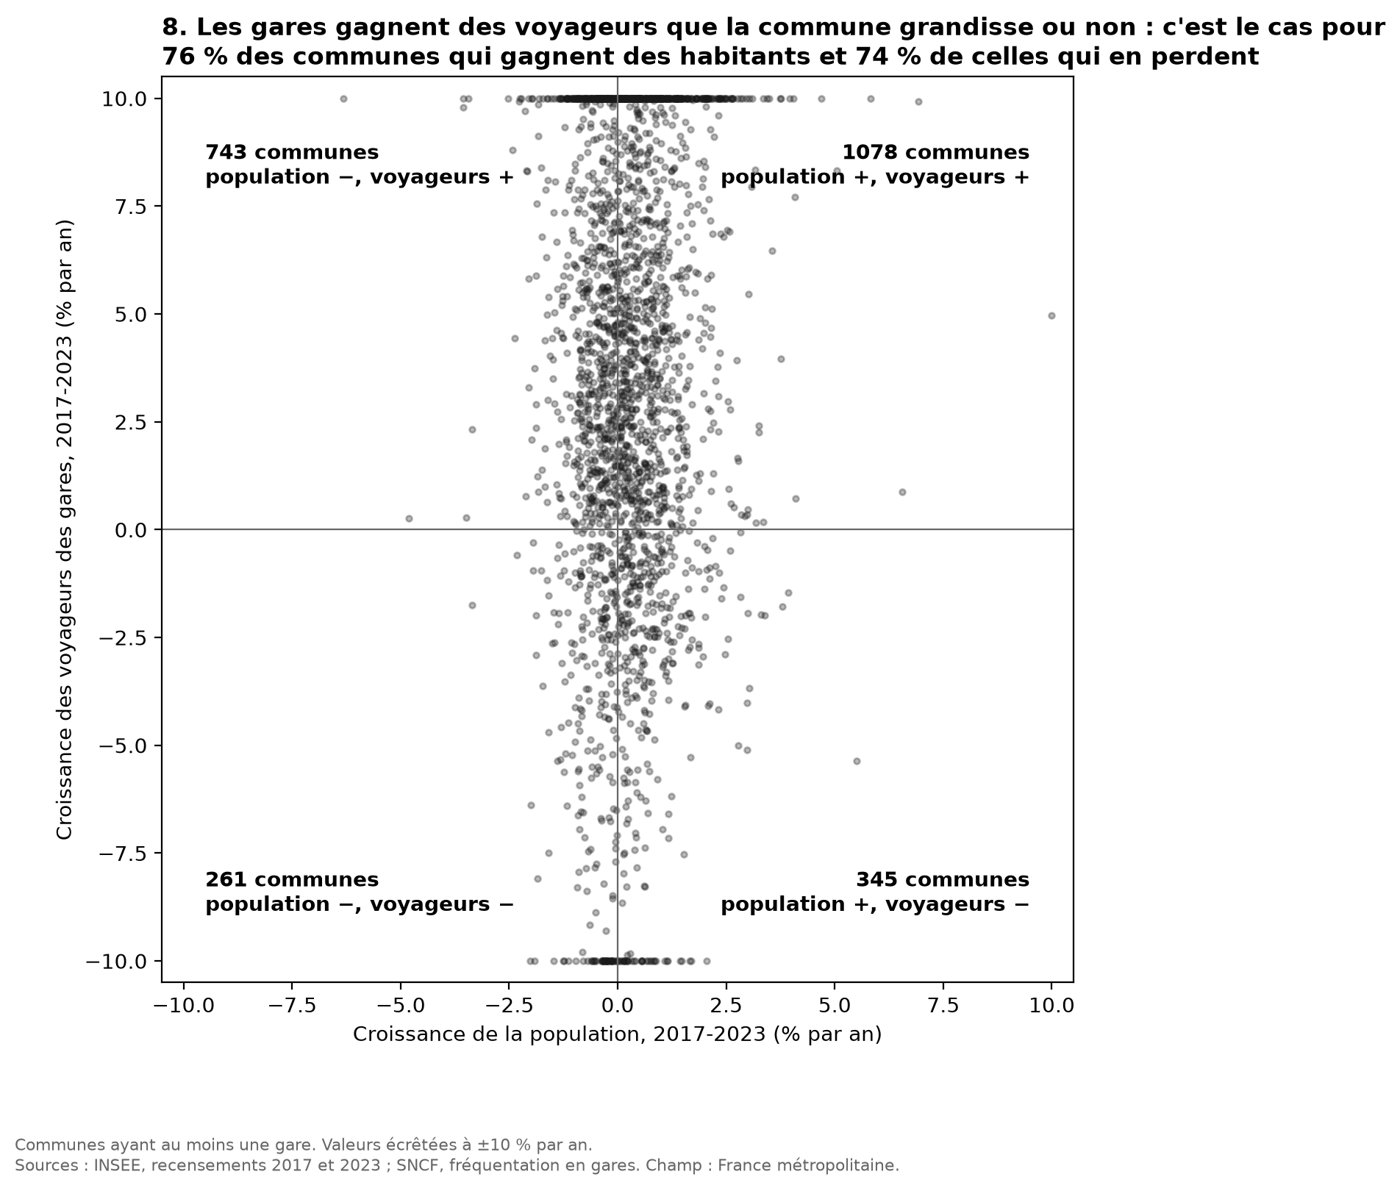

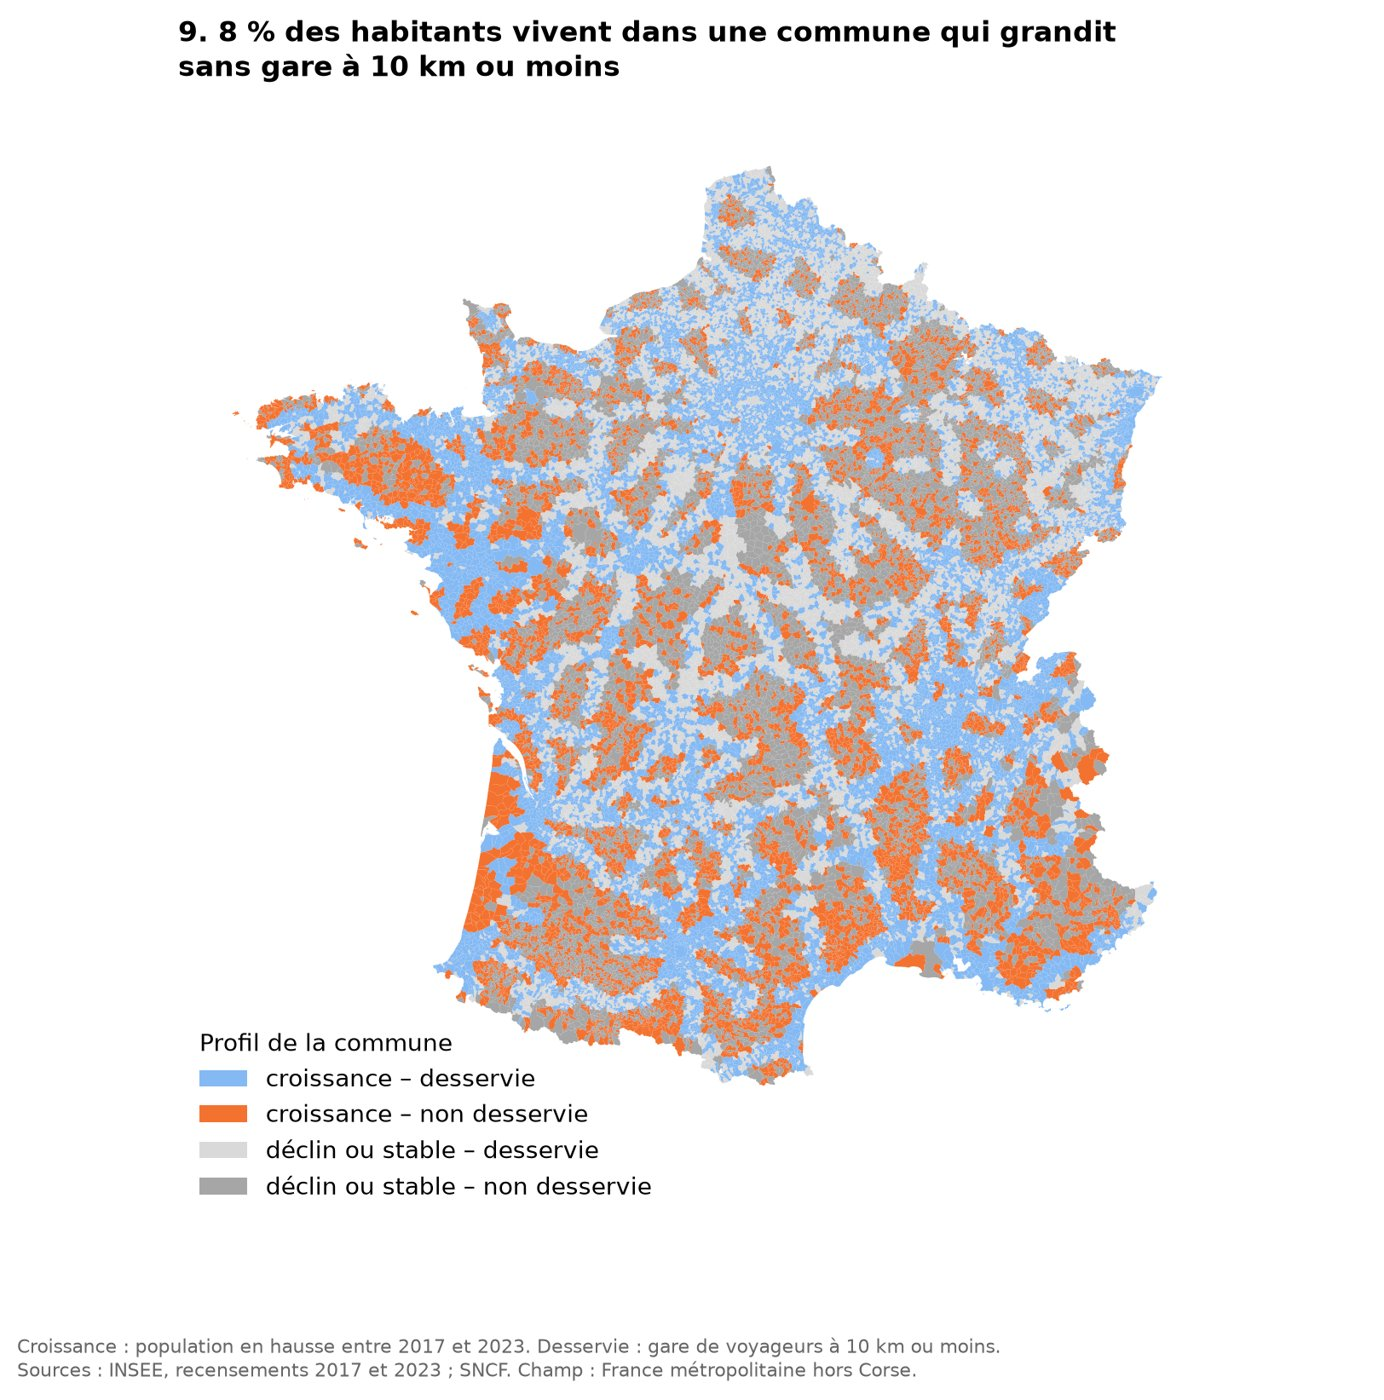

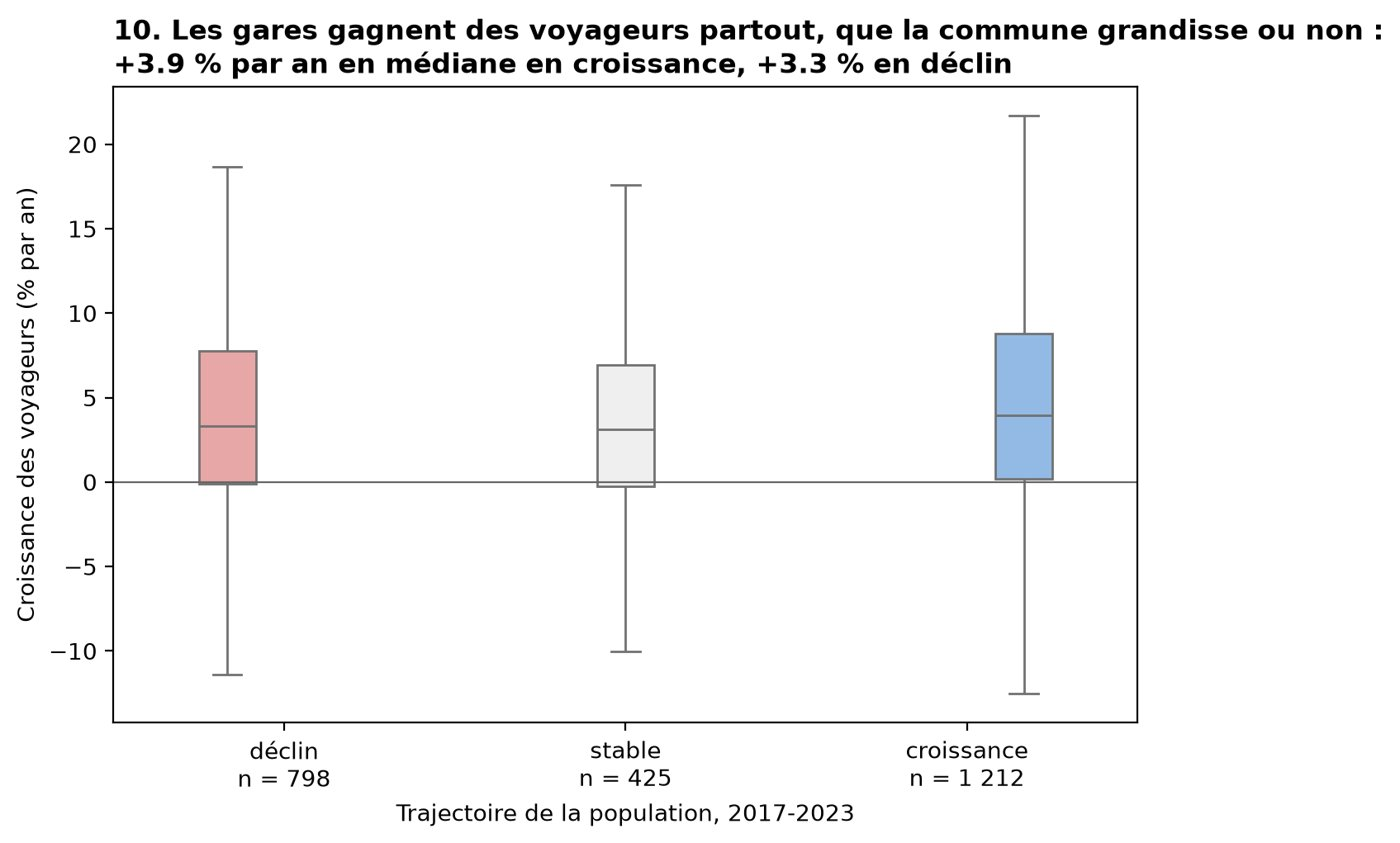

In [7]:
vis.plot_figure("07_carte_gares.png")
vis.plot_figure("08_quadrants.png")
vis.plot_figure("09_carte_profils.png")
vis.plot_figure("10_voyageurs_trajectoire.png")

In [8]:
part_pop, part_voy = build_parts_croissance(communes, gares_annees, fin)
print(f"Communes en croissance : {part_pop:.0f} % de la population, mais {part_voy:.0f} % des voyageurs")

avec_gare = communes.dropna(subset=["tcam_pop_2017_2023", "tcam_voyageurs_2017_2023"])
hausse_voy = avec_gare["tcam_voyageurs_2017_2023"] > 0
print(f"Gares en hausse : {hausse_voy[avec_gare['tcam_pop_2017_2023'] > 0].mean() * 100:.0f} % des communes qui grandissent, "
      f"{hausse_voy[avec_gare['tcam_pop_2017_2023'] < 0].mean() * 100:.0f} % de celles qui déclinent")
correlation = avec_gare["tcam_pop_2017_2023"].corr(avec_gare["tcam_voyageurs_2017_2023"], method="spearman")
print(f"Corrélation entre croissance de la population et des voyageurs : {correlation:.2f}")

sans_gare = communes["profil"] == "croissance – non desservie"
print(f"Communes qui grandissent sans gare à {config['seuil_desservie_km']} km : {sans_gare.sum():,}".replace(",", " "))

Communes en croissance : 67 % de la population, mais 54 % des voyageurs
Gares en hausse : 76 % des communes qui grandissent, 74 % de celles qui déclinent
Corrélation entre croissance de la population et des voyageurs : 0.07
Communes qui grandissent sans gare à 10 km : 6 611


Les voyageurs augmentent presque partout, que la commune gagne des habitants ou non : la fréquentation
des gares ne suit pas la démographie. Les communes qui grandissent pèsent moins dans le trafic que dans la
population, et une partie de cette croissance se fait loin du rail, dans des communes rurales sans gare proche.

## 5. Qui dépend de la voiture, et qui vit loin d'une gare ?

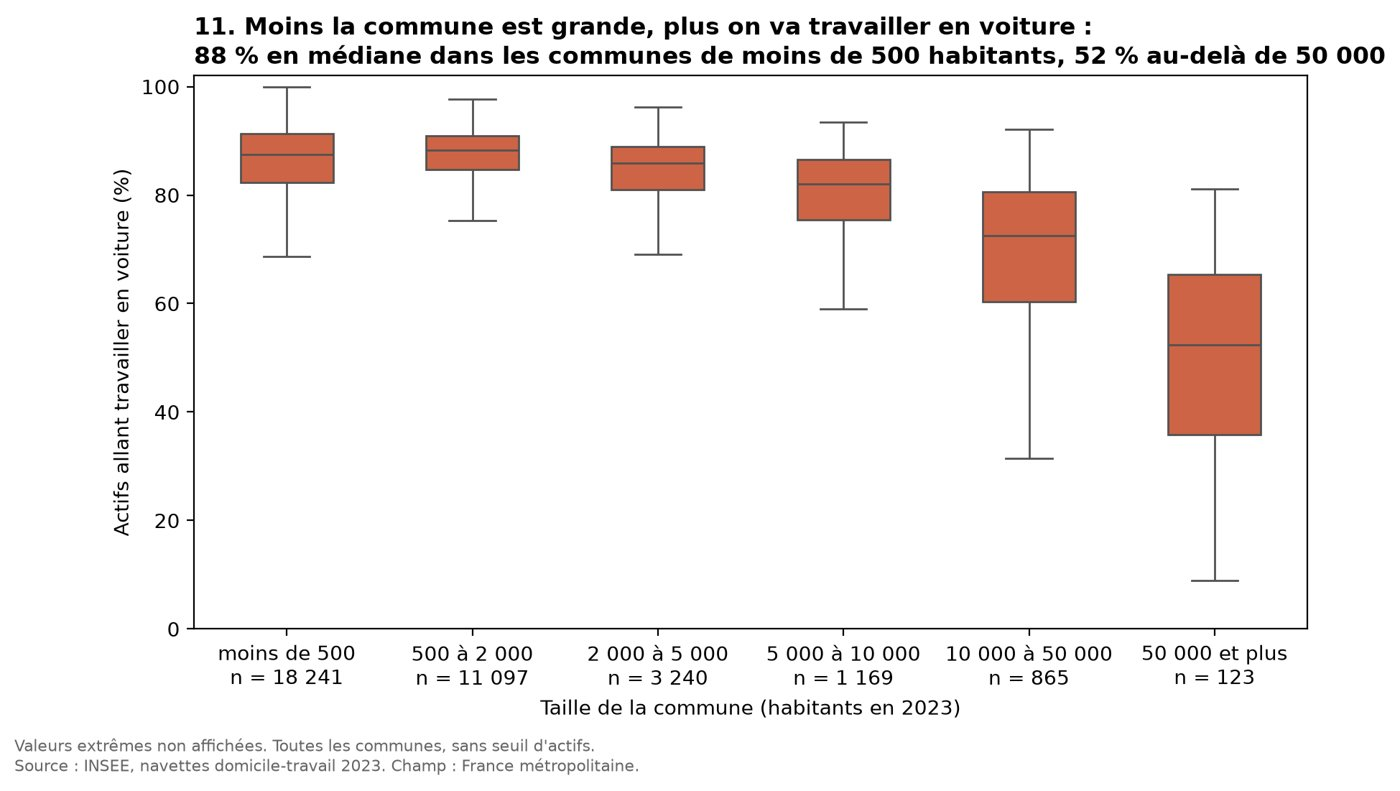

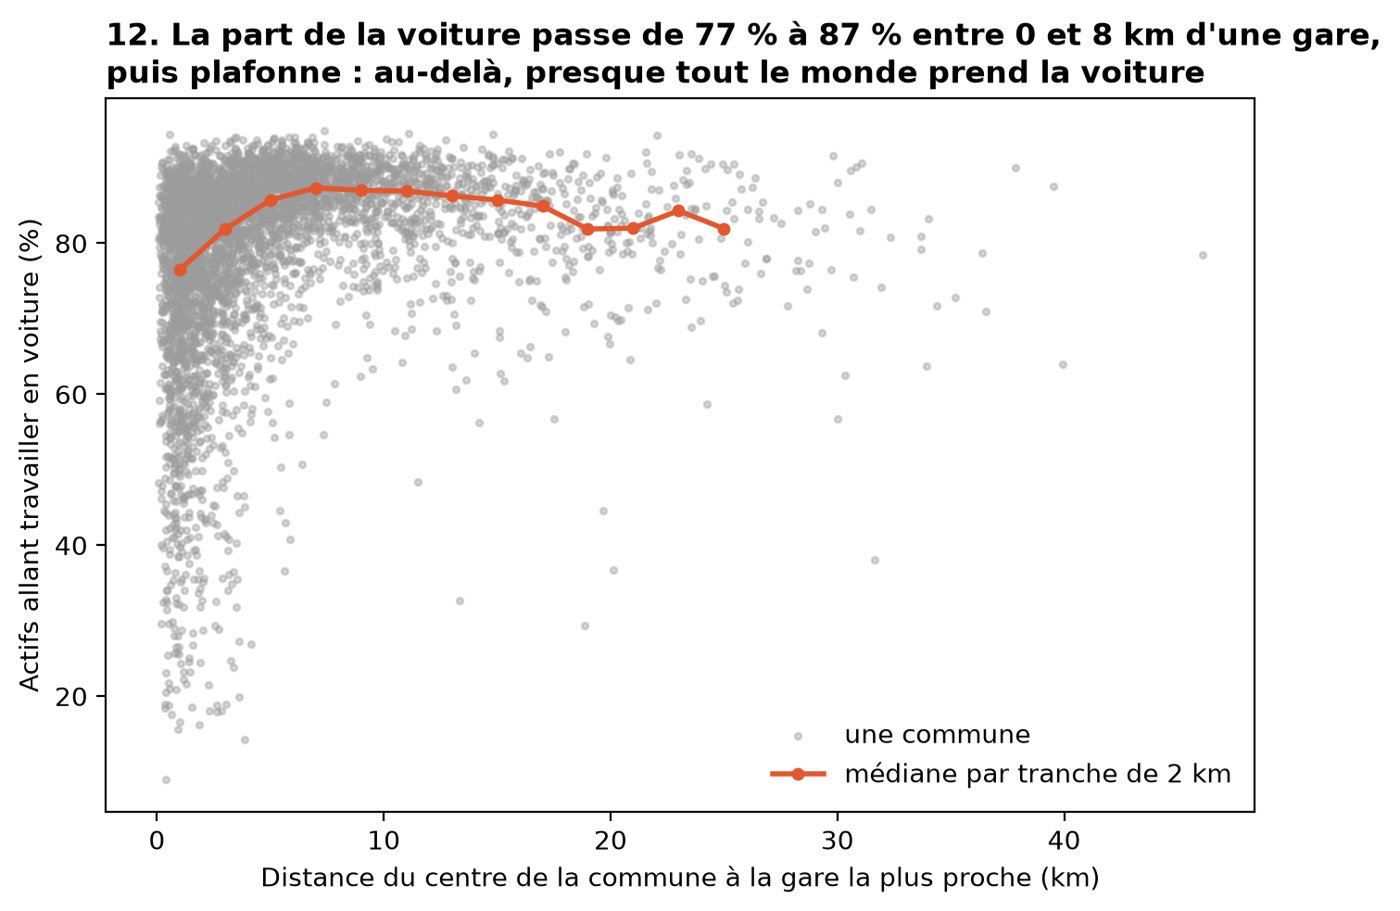

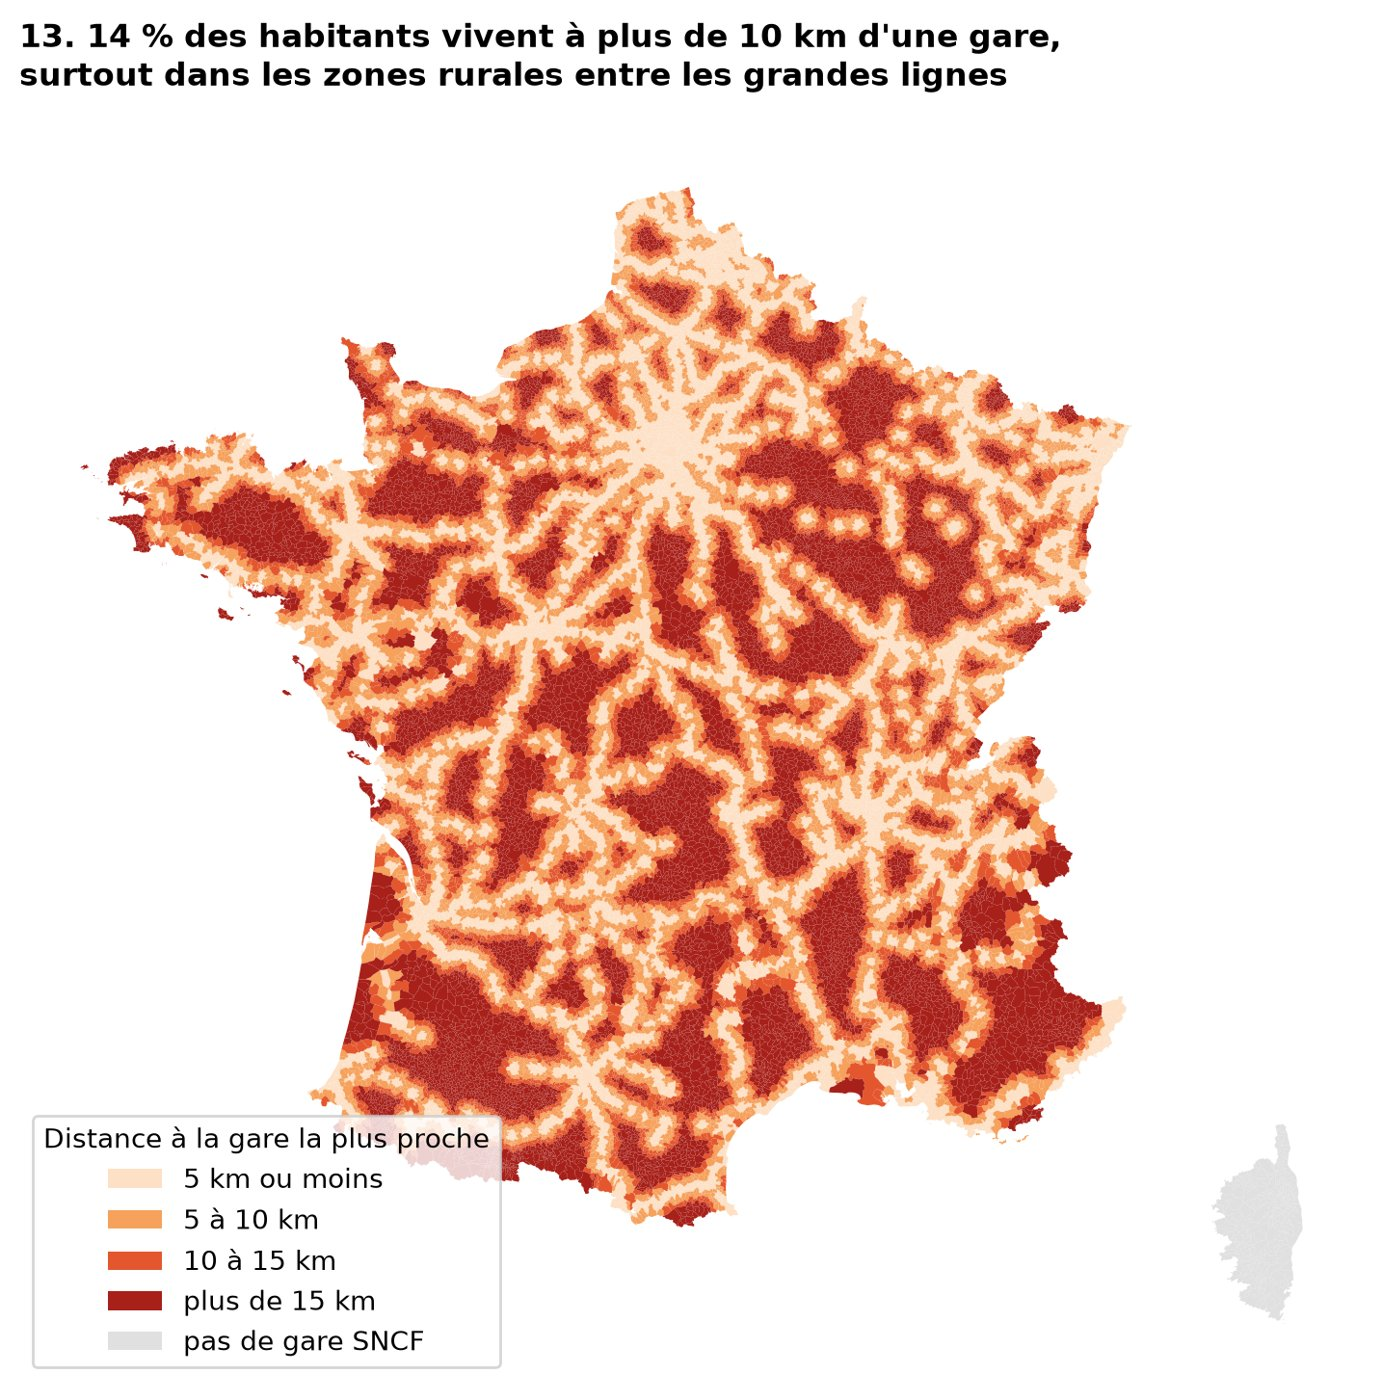

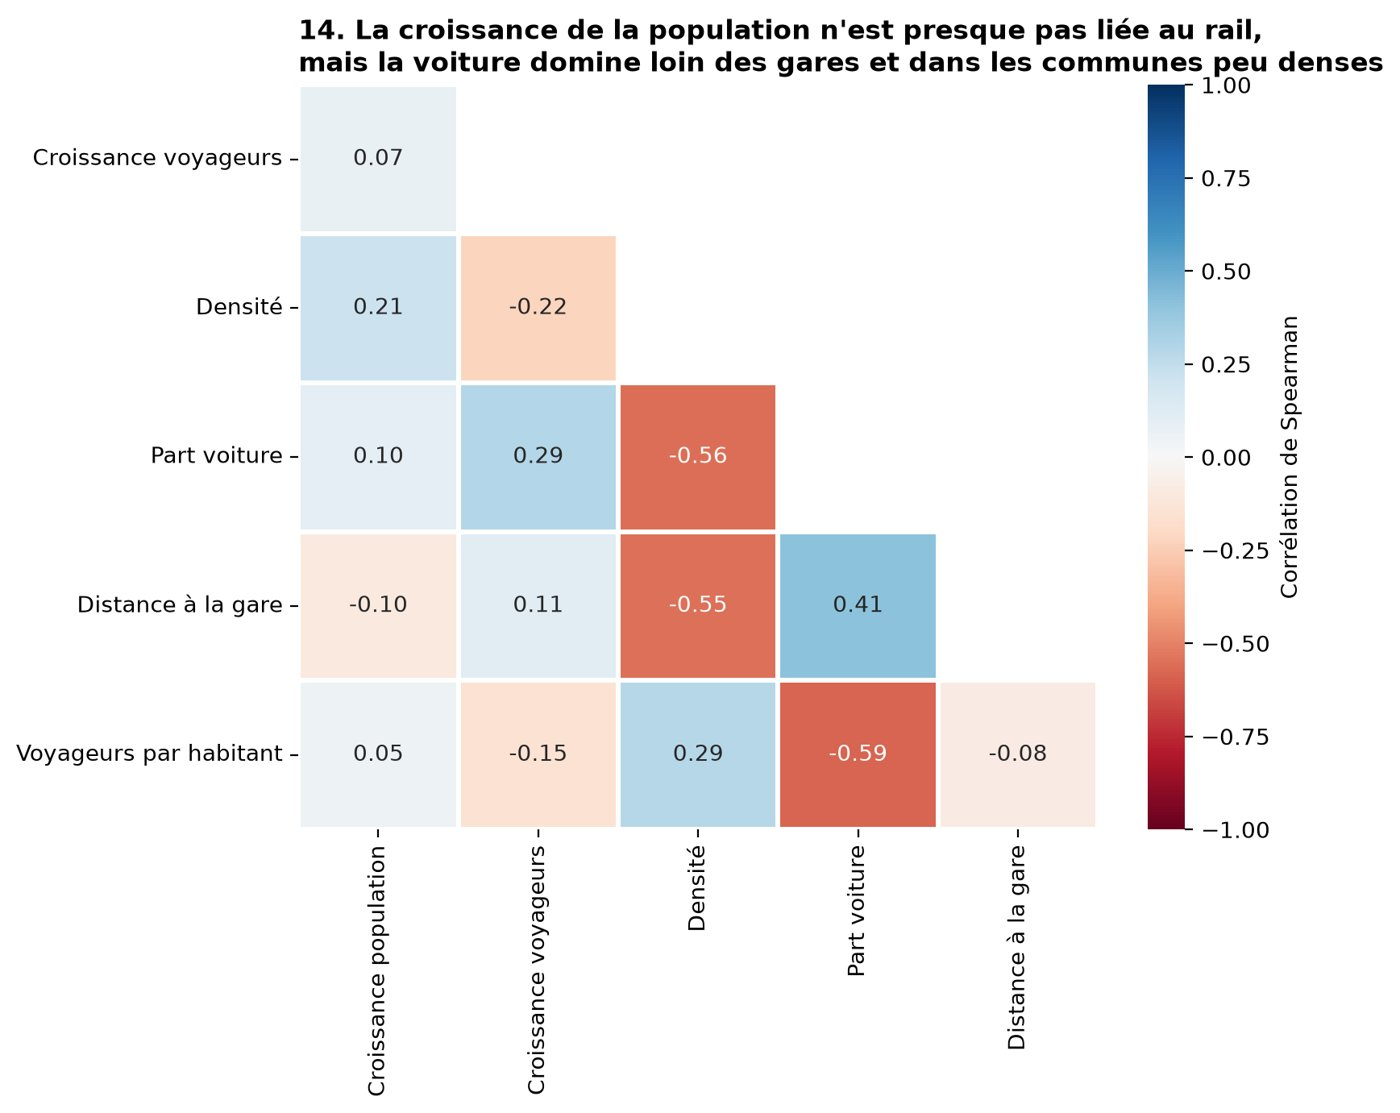

In [9]:
vis.plot_figure("11_voiture_taille.png")
vis.plot_figure("12_voiture_distance.png")
vis.plot_figure("13_carte_distance_gare.png")
vis.plot_figure("14_correlations.png")

In [10]:
medianes = communes.groupby("classe_taille", observed=True)["part_voiture_toutes_2023"].median()
print(f"Part de la voiture (médiane) : {medianes.iloc[0]:.0f} % sous 500 habitants, {medianes.iloc[-1]:.0f} % au-delà de 50 000")
for annee in [debut, fin]:
    print(f"Part de la voiture en {annee}, tous actifs : {communes[f'actifs_voiture_{annee}'].sum() / communes[f'actifs_{annee}'].sum() * 100:.1f} %")

avec_distance = communes.dropna(subset=["dist_gare_km"])
loin = avec_distance["dist_gare_km"] > config["seuil_desservie_km"]
print(f"Habitants à plus de {config['seuil_desservie_km']} km d'une gare : "
      f"{avec_distance.loc[loin, 'pop_2023'].sum() / avec_distance['pop_2023'].sum() * 100:.0f} %")

Part de la voiture (médiane) : 88 % sous 500 habitants, 52 % au-delà de 50 000
Part de la voiture en 2017, tous actifs : 70.3 %
Part de la voiture en 2023, tous actifs : 68.9 %
Habitants à plus de 10 km d'une gare : 14 %


La voiture domine dans les petites communes et loin des gares ; sa part recule un peu entre les deux
recensements, mais reste majoritaire. La distance à la gare compte surtout dans les premiers kilomètres :
au-delà, presque tout le monde prend la voiture.

## 6. Analyse statistique et ACP

Le notebook `05_analyse_mobilites` complète l'analyse des graphiques, par l'intermédiaire d'indices de concentration (Gini, Hoover, Theil), celle des 
contributions à la croissance par taille de commune, une typologie des soldes naturel et migratoire, puis deux
analyses en composantes principales. La première oppose les communes denses, peuplées et bien desservies aux
communes éloignées où la voiture domine. La seconde, sur les communes avec gare, montre que le niveau de
fréquentation va avec la densité, la taille de la commune et les transports collectifs, tandis que sa
progression forme une dimension à part : fréquenter beaucoup une gare et la voir progresser sont deux
choses distinctes.

## 7. Bonus : le train face à l'avion

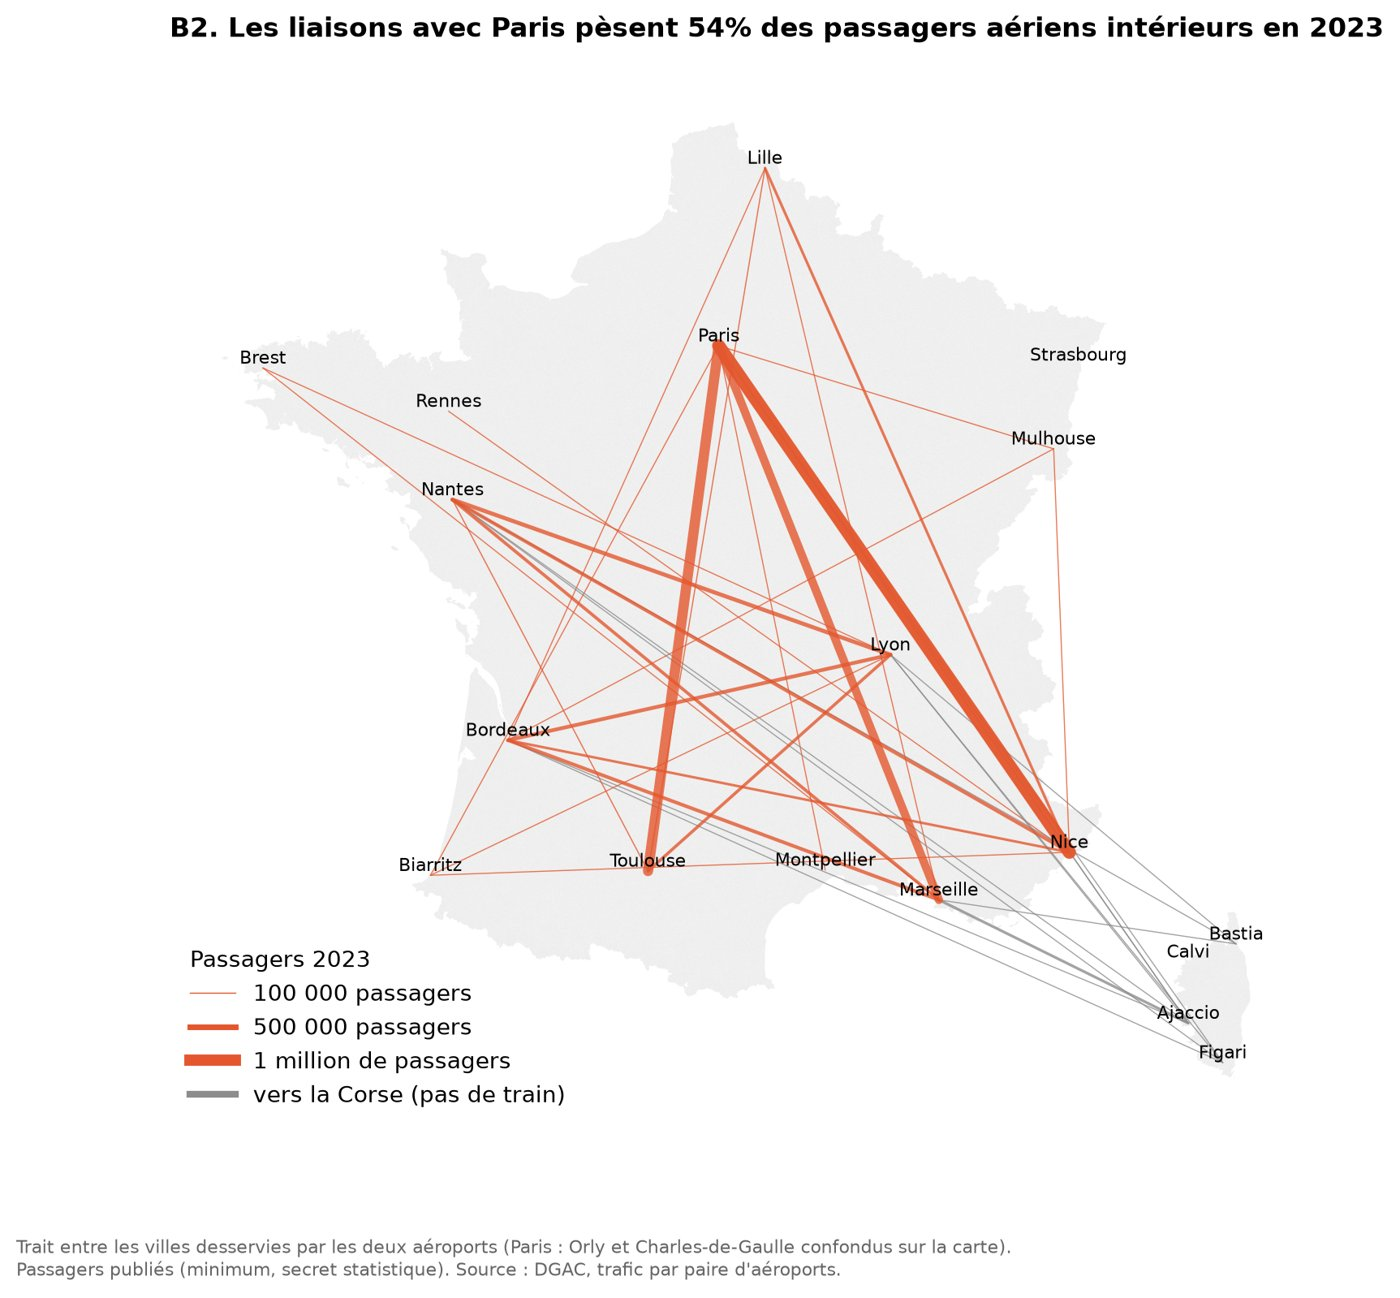

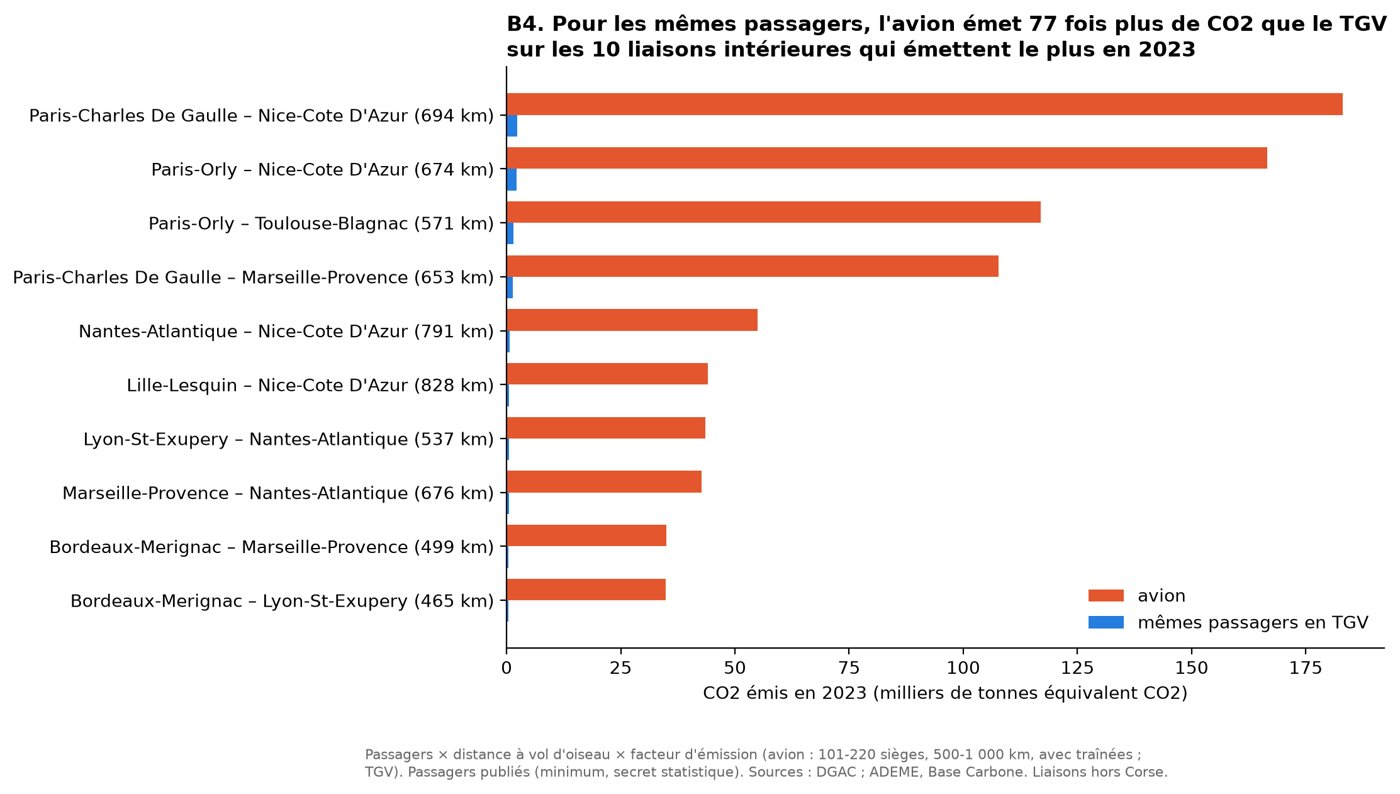

In [11]:
vis.plot_figure("B2_carte_liaisons.png")
vis.plot_figure("B4_co2_avion_tgv.png")

In [12]:
hors_corse = liaisons.dropna(subset=[f"co2_tgv_t_{fin}"])
rapport = hors_corse[f"co2_avion_t_{fin}"].sum() / hors_corse[f"co2_tgv_t_{fin}"].sum()
print(f"Pour les mêmes passagers, l'avion émet {rapport:.0f} fois plus de CO2 que le TGV")

communs = liaisons[liaisons["mois_communs"] > 0]
continent = communs[~(communs["code_oaci_1"].str.startswith("LFK") | communs["code_oaci_2"].str.startswith("LFK"))]
baisse = continent[f"passagers_communs_{fin}"] < continent[f"passagers_communs_{debut}"]
courtes = continent["dist_km"] < 600
print(f"Liaisons en baisse : {baisse[courtes].sum()} sur {courtes.sum()} sous 600 km, {baisse[~courtes].sum()} sur {(~courtes).sum()} au-delà")

Pour les mêmes passagers, l'avion émet 77 fois plus de CO2 que le TGV
Liaisons en baisse : 6 sur 8 sous 600 km, 3 sur 10 au-delà


L'avion recule sur les liaisons courtes, où le train est une alternative, et progresse sur les longues
distances et vers la Corse. Cette forte préférence pour l'avion sur des distances plus longues conduit à de très fortes émissions en C02, qui pourraient être limitées s'il y avait une plus forte préférence pour le train. 

## 8. Limites

- **Fréquentation** : les voyageurs sont comptés par gare, et non par trajet ; on ne sait pas où vont les habitants.
- **Années** : la fréquentation est disponible de 2017 à 2023 ; les années 2015, 2016 et 2024 prévues au départ manquent.
- **Navettes** : le recensement ne distingue pas le train des autres transports en commun.
- **Trafic aérien** : à cause du secret statistique, la DGAC ne publie pas tous les mois ; les passagers sont un minimum,
  et l'évolution est mesurée sur les seuls mois publiés les deux années.
- **Bonus** : sans table horaire, la durée du train n'est pas connue. Par soucis de temps, un seul facteur d'émission a été retenu pour l'avion, alors qu'il y a une grande hétérogénéité des émissions, liées à l'avion.

## 9. Conclusion

Le rail ne suit pas la France qui grandit. La fréquentation des gares augmente presque partout, que la
commune gagne ou perde des habitants : son niveau suit la taille et la densité des villes, et sa
progression n'est presque pas liée à la croissance démographique. Une partie de la croissance se fait loin des gares, dans des communes où la voiture reste
indispensable. Pour les longs trajets intérieurs, l'avion recule là où le train est compétitif, ce qui
montre l'intérêt d'une offre ferroviaire adaptée.

## Organisation du dépôt

| Notebook | Contenu |
|---|---|
| `notebooks/01_donnees` | collecte et nettoyage de chaque source |
| `notebooks/02_base_finale` | jointures et variables |
| `notebooks/03_graphiques` | les 15 graphiques |
| `notebooks/04_bonus_train_avion` | le bonus |
| `notebooks/05_analyse_mobilites` | statistiques et ACP |

Les fonctions sont dans `src/`, les paramètres dans `config.yaml`. L'installation et l'ordre d'exécution
sont décrits dans le `README.md`.